# OSAAcquire.ipynb

A notebook for collecting data with the PIC injected in reverse.

# Imports

In [ ]:
import numpy as np
import matplotlib
matplotlib.rc_file('D:\\Active_PIC\\matplotlibrc')
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import time
import importlib
import os, sys
%matplotlib inline

import TLX2, PM, XPOW, TEC, OSA

import logging
logging.basicConfig(level=logging.DEBUG,
                    format='%(name)-12s: %(levelname)-8s %(message)s',
                    handlers=[logging.StreamHandler(sys.stdout)],
                   )

# Initialize hardware

In [ ]:
tlx = TLX2.TLX()
pm = PM.PM()
tec = TEC.TEC()

tlx.set_voa(1.0)
tlx.laser_on()
# tec.on()

VOA set to 1.0 dB.

-- INITIALIZING METER --


Connecting to power meter...
Connected devices: 
	"b'USB0::0x1313::0x8078::P0015519::INSTR'"
P0015519 0x8078
Internal wavelength: 1590.0


# Stream powers and temperatures

In [ ]:
xpow = XPOW.XPOW()

channel = 67
xpow.apply_voltage(channel, 0)

In [43]:
xpow.apply_voltage(channel, 0)
tlx.laser_off()

In [44]:
tlx.laser_on()

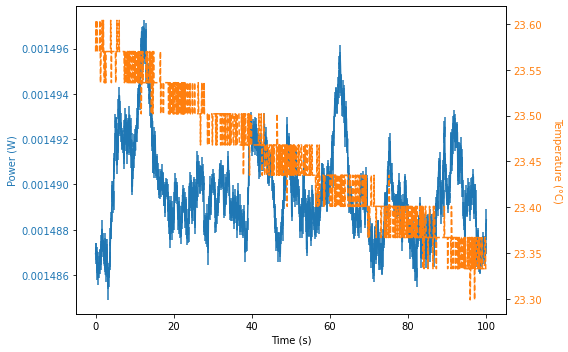

In [46]:
duration, iter, std = 100, 10, True
data_dir = "D:\\Active_PIC\\2026-02-26\\ReverseInjection\\"
device_name = "Device5b_2x3Tri"
input_name = "Device5b_I17_O25_2x3Tri"


times, temps = [time.time()], [tec.read_temperature()]
power = pm.read_power(iter=iter, std=std)

if std:
    powers, sigmas = [power[0]], [power[1]]
else:
    powers = [power]
time_end = times[0] + duration

while time.time() < time_end:
    power = pm.read_power(iter=iter, std=std)
    times.append(time.time())
    temps.append(tec.read_temperature())
    if std:
        powers.append(power[0])
        sigmas.append(power[1])
    else:
        powers.append(power)

times, temps, powers = np.array(times), np.array(temps), np.array(powers)
np.save(f"{data_dir}{device_name}\\{input_name}_time.npy", times)
np.save(f"{data_dir}{device_name}\\{input_name}_temp.npy", temps)
np.save(f"{data_dir}{device_name}\\{input_name}_power.npy", powers)
if std:
    sigmas = np.array(sigmas)
    np.save(f"{data_dir}{device_name}\\{input_name}_sigma.npy", sigmas)

fig, ax1 = plt.subplots(figsize=(8,5))

ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Power (W)", color='C0')
if std:
    ax1.errorbar(times-times[0], powers, sigmas, color='C0')
else:
    ax1.plot(times, powers, color='C')
ax1.tick_params(axis='y', labelcolor='C0')

# Create right axis
ax2 = ax1.twinx()  # share x-axis
ax2.set_ylabel("Temperature (°C)", color='C1', rotation=270, labelpad=20)
ax2.plot(times-times[0], temps, color='C1', linestyle='--')
ax2.tick_params(axis='y', labelcolor='C1')

plt.tight_layout()
plt.show()

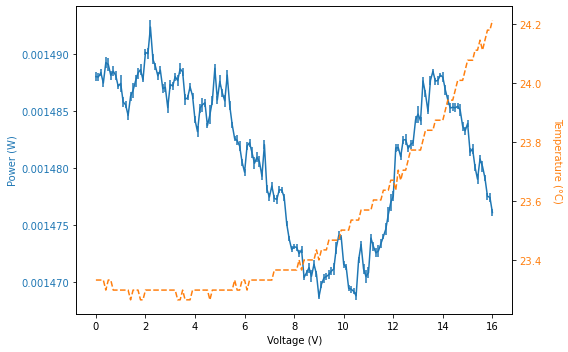

In [ ]:
iter, std =  10, True
data_dir = "D:\\Active_PIC\\2026-02-26\\ReverseInjection\\"
device_name = "Device5b_2x3Tri"
input_name = "Device5b_I17_O25_2x3Tri"

voltages = np.arange(0, 16.1, 0.1)
times, temps, powers, sigmas, readout_voltages, readout_currents = [], [], [], [], [], []

for voltage in voltages:
    xpow.apply_voltage(channel, voltage)
    readout_voltage, readout_current, _ = xpow.read_XPOW(channel)
    readout_voltages.append(readout_voltage)
    readout_currents.append(readout_current)

    power = pm.read_power(iter=iter, std=std)
    times.append(time.time())
    temps.append(tec.read_temperature())
    if std:
        powers.append(power[0])
        sigmas.append(power[1])
    else:
        powers.append(power)

times, temps, powers = np.array(times), np.array(temps), np.array(powers)
np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_voltage.npy", voltages)
np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_time.npy", times)
np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_temp.npy", temps)
np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_power.npy", powers)
np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_readoutVoltage.npy", readout_voltages)
np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_readoutCurrent.npy", readout_currents)
if std:
    sigmas = np.array(sigmas)
    np.save(f"{data_dir}{device_name}\\{input_name}_voltageScan_sigma.npy", sigmas)

fig, ax1 = plt.subplots(figsize=(8,5))

ax1.set_xlabel("Voltage (V)")
ax1.set_ylabel("Power (W)", color='C0')
if std:
    ax1.errorbar(voltages, powers, sigmas, color='C0')
else:
    ax1.plot(voltages, powers, color='C')
ax1.tick_params(axis='y', labelcolor='C0')

# Create right axis
ax2 = ax1.twinx()  # share x-axis
ax2.set_ylabel("Temperature (°C)", color='C1', rotation=270, labelpad=20)
ax2.plot(voltages, temps, color='C1', linestyle='--')
ax2.tick_params(axis='y', labelcolor='C1')

plt.tight_layout()
plt.show()

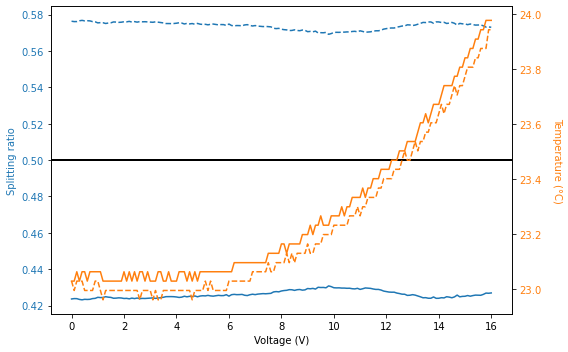

In [25]:
data_dir = "D:\\Active_PIC\\2026-02-26\\ReverseInjection\\"
device_name = "Device5b_2x3Tri"
input_name_1 = "Device5b_I16_O23_2x3Tri"
input_name_2 = "Device5b_I17_O23_2x3Tri"

voltages = np.load(f"{data_dir}{device_name}\\{input_name_1}_voltageScan_voltage.npy")
temps_1 = np.load(f"{data_dir}{device_name}\\{input_name_1}_voltageScan_temp.npy")
temps_2 = np.load(f"{data_dir}{device_name}\\{input_name_2}_voltageScan_temp.npy")
powers_1 = np.load(f"{data_dir}{device_name}\\{input_name_1}_voltageScan_power.npy")
powers_2 = np.load(f"{data_dir}{device_name}\\{input_name_2}_voltageScan_power.npy")
powers_tot = powers_1 + powers_2

fig, ax1 = plt.subplots(figsize=(8,5))

ax1.set_xlabel("Voltage (V)")
# ax1.set_ylabel("Power (W)", color='C0')
ax1.set_ylabel("Splitting ratio", color='C0')
ax1.plot(voltages, powers_1/powers_tot, color='C0')
ax1.plot(voltages, powers_2/powers_tot, color='C0', linestyle='dashed')
ax1.axhline(0.5, color='k', linewidth=2)
# ax1.plot(voltages, powers_tot, color='k', linewidth=2)
ax1.tick_params(axis='y', labelcolor='C0')

# Create right axis
ax2 = ax1.twinx()  # share x-axis
ax2.set_ylabel("Temperature (°C)", color='C1', rotation=270, labelpad=20)
ax2.plot(voltages, temps_1, color='C1')
ax2.plot(voltages, temps_2, color='C1', linestyle='dashed')
ax2.tick_params(axis='y', labelcolor='C1')

plt.tight_layout()
plt.show()

In [50]:
tlx.laser_off()

In [51]:
tec.close()
tlx.close()
pm.close()
xpow.close()

Connection to Arduino closed.
Disconnected from power meter.


# OSA measurements

In [2]:
xpow = XPOW.XPOW()
tec = TEC.TEC()

XPOW        : DEBUG    ------------------------------------------
Chosen XPOW Ports: ['COM4', 'COM6', 'COM8']
------------------------------------------

XPOW        : INFO     XPOW ports created!
XPOW        : DEBUG    Sent XPOW command: "board?" to all ports.
XPOW        : DEBUG    COM4answer = {D:1:TOP}
XPOW        : DEBUG    COM6answer = {D:2:MIDDLE}
XPOW        : DEBUG    COM8answer = {D:3:BOTTOM}
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:1:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {1:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {2:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4a

In [59]:
osa = OSA.OSA()
# osa.close()

OSAs found: 1
Opening first OSA...


In [41]:
tec.read_temperature()

36.748

In [44]:
PS1, PS2, V1, V2 = 61, 62, 9.55, 10.38
xpow.apply_voltage(PS1, 0)
xpow.apply_voltage(PS2, 0)
xpow.apply_voltage(channel, 0)

XPOW        : DEBUG    Sent XPOW command: "CH:21:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:21:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:21:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {21:2.224:19.3220}
XPOW        : DEBUG    Channel 61 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:22:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:22:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:22:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {22:2.649:24.8905}
XPOW        : DEBUG    Channel 62 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:1:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {1:8.477:72.7729}
XPOW        : DEBUG    Channel 41 set to 0 V.


XPOW        : DEBUG    Sent XPOW command: "CH:28:VOLT:11.38" to port "COM6".
XPOW        : DEBUG    COM6answer = {:28:VOLT:11.38:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:28:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {28:11.005:99.3027}
XPOW        : DEBUG    Channel 68 set to 11.38 V.
XPOW        : DEBUG    Sent XPOW command: "CH:29:VOLT:11.92" to port "COM6".
XPOW        : DEBUG    COM6answer = {:29:VOLT:11.92:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:29:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {29:11.512:102.9481}
XPOW        : DEBUG    Channel 69 set to 11.92 V.
XPOW        : DEBUG    Sent XPOW command: "CH:3:VOLT:0.0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:3:VOLT:0.0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {3:2.634:20.2590}
XPOW        : DEBUG    Channel 43 set to 0.0 V.
5
Spectrum Acquired! (1.35 sec)
Spectrum Acquired! (1.64 sec)
Spectrum Acquired!

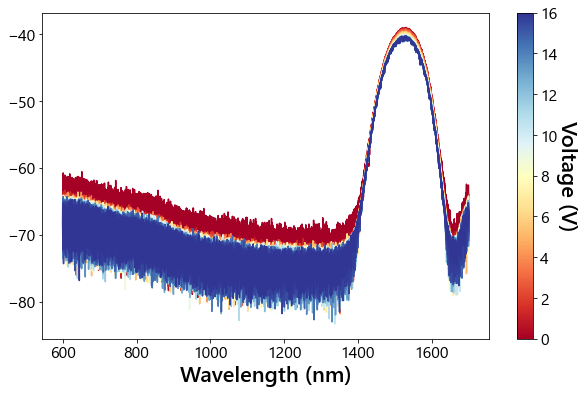

In [60]:
device_name, output, channel = "Device7a_I21_1x5Tri", 40, 43
data_dir = f'D:\\Active_PIC\\SpectroscopyScans\\{device_name}\\20260508\\'
PS1, PS2, V1, V2 = 68, 69, 11.38, 11.92
xpow.apply_voltage(PS1, V1)
xpow.apply_voltage(PS2, V2)
V1_str, V2_str = f"{V1:0.3f}".replace('.', 'p'), f"{V2:0.3f}".replace('.', 'p')
ext = f'_Ch{PS1}_V{V1_str}_Ch{PS2}_V{V2_str}'
# ext = ''

input_name = f"{device_name}_O{output}{ext}_Ch{channel}"
directory_path = f"{data_dir}{device_name}_O{output}{ext}\\"

os.makedirs(directory_path, exist_ok=True)

voltages = np.arange(0, 16.1, 0.2)
temps = []
readout = []

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(voltages), vmax=np.max(voltages))
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue

for voltage in voltages:
    xpow.apply_voltage(channel, voltage)
    time.sleep(2)
    voltage_str = f"{voltage:.3f}".replace('.', 'p')
    spectrum, sigma = osa.read_spectrum(navg=5, plot=False, filename=f"{directory_path}{input_name}_V{voltage_str}")
    temps.append(tec.read_temperature())
    readout.append(xpow.read_XPOW(channel))
    
    color = cmap(norm(voltage))
    plt.plot(spectrum[0], spectrum[1], label=f"{voltage:0.3f} V", color=color)

# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Voltage (V)", rotation=270, labelpad=20)

plt.show()  

header_str = f'inputVoltage{channel},readoutVoltage{channel},readoutCurrent{channel},readoutPower{channel},temperature'
np.savetxt(f'{directory_path}{input_name}.log', np.vstack([voltages, np.array(readout).T, temps]).T, delimiter=',', header=header_str)

Sanny's experiment

In [34]:
osa.close()
# osa = OSA.OSA()

OSA         : INFO     Disconnected from OSA.


In [25]:
xpow.apply_voltage(PS1, 0)
xpow.apply_voltage(PS2, 10)
xpow.apply_voltage(PS3, V3)


XPOW        : DEBUG    Sent XPOW command: "CH:24:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:24:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:24:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {24:0.002:0.0000}
XPOW        : DEBUG    Channel 64 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:23:VOLT:10" to port "COM6".
XPOW        : DEBUG    COM6answer = {:23:VOLT:10:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:23:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {23:3.775:35.0535}
XPOW        : DEBUG    Channel 63 set to 10 V.
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {2:0.144:0.0000}
XPOW        : DEBUG    Channel 42 set to 0 V.


XPOW        : DEBUG    Sent XPOW command: "CH:24:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:24:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:24:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {24:0.206:-0.2000}
XPOW        : DEBUG    Channel 64 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:23:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:23:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:23:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {23:5.325:48.3180}
XPOW        : DEBUG    Channel 63 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {2:0.002:0.0000}
XPOW        : DEBUG    Channel 42 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:23:VOLT:0.0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:2

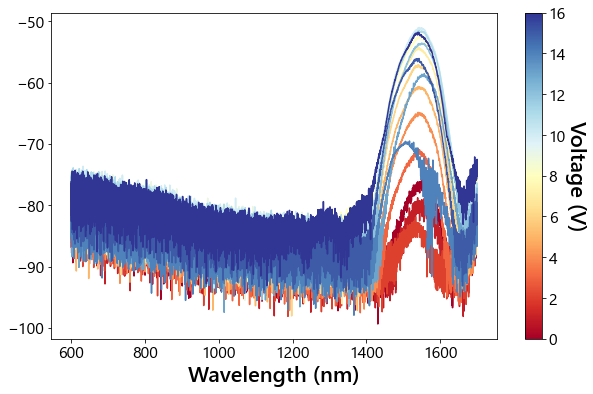

In [ ]:
import matplotlib.cm as cm

data_dir = "C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-04-21-Active-Tricouplers\Device-2x5\\2-T1-OFF-T2-ON-P2-Scan\\2-I2\\"
PS1, PS2, PS3, V1, V2, V3 = 64, 63, 42, 0, 0, 0
channel, output_name = PS2, 'I2'
xpow.apply_voltage(PS1, V1)
xpow.apply_voltage(PS2, V2)
xpow.apply_voltage(PS3, V3)

voltages = np.arange(0, 16.1, 1)
temps = []
readout = []

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(voltages), vmax=np.max(voltages))
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
for voltage in voltages:
    xpow.apply_voltage(channel, voltage)
    time.sleep(10)
    voltage_str = f'{voltage:.0f}'
    spectrum, sigma = osa.read_spectrum(navg=3, plot=False, filename=f"{data_dir}{output_name}_V{voltage_str}")
    temps.append(tec.read_temperature())
    readout.append(xpow.read_XPOW(channel))

    color = cmap(norm(voltage))
    plt.plot(spectrum[0], spectrum[1], label=f"{voltage:0.3f} V", color=color)

# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Voltage (V)", rotation=270, labelpad=20)

plt.show()  

header_str = f'inputVoltage{channel},readoutVoltage{channel},readoutCurrent{channel},readoutPower{channel},temperature'
np.savetxt(f'{data_dir}{output_name}.log', np.vstack([voltages, np.array(readout).T, temps]).T, delimiter=',', header=header_str)

In [111]:
osa.close()
# osa = OSA.OSA()

OSA         : INFO     Disconnected from OSA.


XPOW        : DEBUG    Sent XPOW command: "CH:31:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:31:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:31:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {31:5.441:48.7051}
XPOW        : DEBUG    Channel 71 set to 0 V.
XPOW        : DEBUG    Sent XPOW command: "CH:31:VOLT:0.0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:31:VOLT:0.0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:31:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {31:0.194:-0.2000}
XPOW        : DEBUG    Channel 71 set to 0.0 V.
3
Spectrum Acquired! (3.73 sec)
Spectrum Acquired! (0.77 sec)
Spectrum Acquired! (0.82 sec)
XPOW        : DEBUG    Sent XPOW command: "CH:31:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {31:0.194:-0.2000}
XPOW        : DEBUG    Sent XPOW command: "CH:31:VOLT:1.0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:31:VOLT:1.0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:31:VAL?

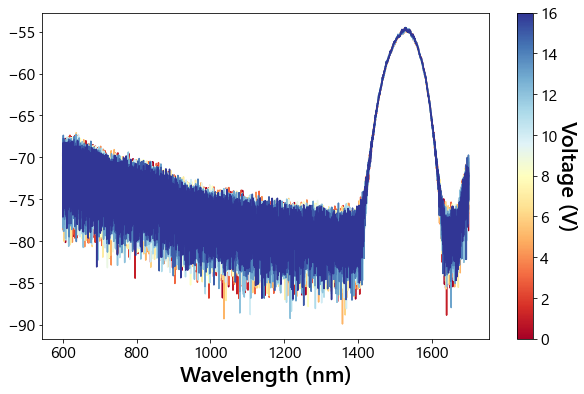

In [112]:
import matplotlib.cm as cm

data_dir = "C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-04-21-Active-Tricouplers\Device-2x3\\2-T1-OFF-T2-ON-Phi-Scan-Photometry\\I3\\"
PS1, V1 = 71, 0
channel, output_name = PS1, 'I3'
xpow.apply_voltage(PS1, V1)

voltages = np.arange(0, 16.1, 1)
temps = []
readout = []

fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(voltages), vmax=np.max(voltages))
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
for voltage in voltages:
    xpow.apply_voltage(channel, voltage)
    time.sleep(10)
    voltage_str = f'{voltage:.0f}'
    spectrum, sigma = osa.read_spectrum(navg=3, plot=False, filename=f"{data_dir}{output_name}_V{voltage_str}")
    temps.append(tec.read_temperature())
    readout.append(xpow.read_XPOW(channel))

    color = cmap(norm(voltage))
    plt.plot(spectrum[0], spectrum[1], label=f"{voltage:0.3f} V", color=color)

# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Voltage (V)", rotation=270, labelpad=20)

plt.show()  

header_str = f'inputVoltage{channel},readoutVoltage{channel},readoutCurrent{channel},readoutPower{channel},temperature'
np.savetxt(f'{data_dir}{output_name}.log', np.vstack([voltages, np.array(readout).T, temps]).T, delimiter=',', header=header_str)

In [113]:
tec.close()
osa.close()
xpow.close()

TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
OSA         : INFO     Disconnected from OSA.
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:1:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {1:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {2:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:3:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {3:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:4:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:4:VOLT:0:OK}
XPOW   

C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\1-T1-ON-T2-OFF-P1-Scan\1-P1\P1_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\1-T1-ON-T2-OFF-P1-Scan\2-I1\I1_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\1-T1-ON-T2-OFF-P1-Scan\3-I2\I2_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\1-T1-ON-T2-OFF-P1-Scan\4-I3\I3_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\2-T1-OFF-T2-ON-P2-Scan\5-P2\P2_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\2-T1-OFF-T2-ON-P2-Scan\2-I1\I1_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\2-T1-OFF-T2-ON-P2-Scan\3-I2\I2_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x5\2-T1-OFF-T2-ON-P2-Scan\4-I3\I3_V*
matplotlib.colorbar: DEBUG    locator: <matplotlib.colorbar._ColorbarAutoLocator object at 0x0000018FBDCE81F0>
matplotlib.colorb

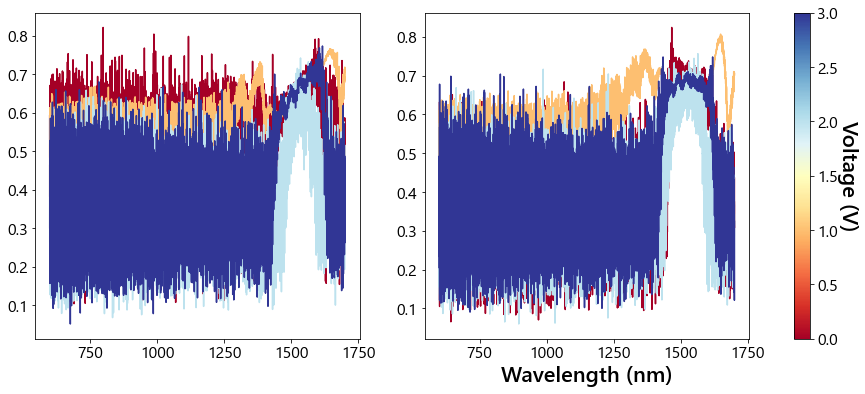

In [92]:
import glob

def read_voltage_scan_spectra(data_dir, prefix, channel, sep=';', delimiter=','):
    ''' Outputs all spectra associated with input filename prefix and modulation channel.

        Parameters
        ----------
        data_dir: string
            Path to directory where data being read in are stored
        prefix: string
            Filename prefix (can include wildcard * to encompass multiple voltage scans)
        channel: integer
            Channel being modulated (in voltage) in data of interest
        sep: string
            Separator used in data files
        
        Returns
        -------
        all_spectra: 3D numpy array
            Collection of spectra (nx2 arrays with wavelength in the first column and spectral power in the second column)
        powers: 1D numpy array
            Powers associated with voltages applied to obtain spectra
        actualvoltages: 1D numpy array
            Measured voltages associated with voltages applied to obtain spectra   
    '''
    # List all files of interest with spectra to plot
    print(data_dir+'%s_V*' % (prefix))
    files = glob.glob(data_dir+'%s_V*' % (prefix))
    
    # Identify all voltages associated with data
    dats = np.genfromtxt(glob.glob(f'{data_dir}{prefix}*.log')[0], names=True, comments="#", delimiter=',')
    voltages = dats[f'inputVoltage{channel}']

    # Average and store all spectra associated with the same voltage applied to the same channel
    all_spectra = []
    for v in voltages:
        v_str = f'{v:.0f}'
        files = glob.glob(f'{data_dir}{prefix}_V{v_str}*') # All spectra of a given voltage
        spectra_v = [] 
        for filename in files:
            # Read and store spectrum
            wav, flux = PIC.read_ThorSpectra(filename, log=False, delimiter=delimiter)
            spectra_v.append(np.vstack([wav, flux]).T)      
        
        # Average all iterations      
        spectrum_v = np.mean(spectra_v, axis=0)
        all_spectra.append(spectrum_v)

    all_spectra = np.array(all_spectra)

    return voltages, all_spectra

data_dir = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-04-21-Active-Tricouplers\Device-2x5\\1-T1-ON-T2-OFF-P1-Scan\\'
voltages, T1_P1 = read_voltage_scan_spectra(f'{data_dir}1-P1\\', 'P1', 64, sep=',', delimiter=';')
wav_ref, T1_P1 = np.copy(T1_P1[0][:,0]), np.copy(T1_P1[0][:,1])
_, T1_I1 = read_voltage_scan_spectra(f'{data_dir}2-I1\\', 'I1', 64, sep=',', delimiter=';')
T1_I1 = np.array([np.interp(wav_ref, T1_I1[i][:,0], T1_I1[i][:,1]) for i in range(len(voltages))])
_, T1_I2 = read_voltage_scan_spectra(f'{data_dir}3-I2\\', 'I2', 64, sep=',', delimiter=';')
T1_I2 = np.array([np.interp(wav_ref, T1_I2[i][:,0], T1_I2[i][:,1]) for i in range(len(voltages))])
_, T1_I3 = read_voltage_scan_spectra(f'{data_dir}4-I3\\', 'I3', 64, sep=',', delimiter=';')
T1_I3 = np.array([np.interp(wav_ref, T1_I3[i][:,0], T1_I3[i][:,1]) for i in range(len(voltages))])

data_dir = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-04-21-Active-Tricouplers\Device-2x5\\2-T1-OFF-T2-ON-P2-Scan\\'
_, T2_P2 = read_voltage_scan_spectra(f'{data_dir}5-P2\\', 'P2', 63, sep=',', delimiter=';')
T2_P2 = np.array([np.interp(wav_ref, T2_P2[i][:,0], T2_P2[i][:,1]) for i in range(len(voltages))])
_, T2_I1 = read_voltage_scan_spectra(f'{data_dir}2-I1\\', 'I1', 63, sep=',', delimiter=';')
T2_I1 = np.array([np.interp(wav_ref, T2_I1[i][:,0], T2_I1[i][:,1]) for i in range(len(voltages))])
_, T2_I2 = read_voltage_scan_spectra(f'{data_dir}3-I2\\', 'I2', 63, sep=',', delimiter=';')
T2_I2 = np.array([np.interp(wav_ref, T2_I2[i][:,0], T2_I2[i][:,1]) for i in range(len(voltages))])
_, T2_I3 = read_voltage_scan_spectra(f'{data_dir}4-I3\\', 'I3', 63, sep=',', delimiter=';')
T2_I3 = np.array([np.interp(wav_ref, T2_I3[i][:,0], T2_I3[i][:,1]) for i in range(len(voltages))])

T1_split = T1_I2/(T1_I1 + T1_I2 + T1_I3)
T2_split = T2_I2/(T2_I1 + T2_I2 + T2_I3)
wav_ref = 10000000/wav_ref

fig, ax = plt.subplots(1, 2, figsize=(16,6))
vmin, vmax = 0, 3
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
voltages_range = (voltages>=vmin) * (voltages<=vmax)

for i, voltage in enumerate(voltages[voltages_range]):
    color = cmap(norm(voltage))
    ax[0].plot(wav_ref, T1_split[voltages_range][i], color=color)
    ax[1].plot(wav_ref, T2_split[voltages_range][i], color=color)

# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Voltage (V)", rotation=270, labelpad=20)

plt.show()

C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x3\1-T1-ON-T2-OFF-Phi-Scan-Photometry\I1\I1_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x3\1-T1-ON-T2-OFF-Phi-Scan-Photometry\I2\I2_V*
C:\Users\Pradip\Desktop\Sanny-PIC\2026-04-21-Active-Tricouplers\Device-2x3\1-T1-ON-T2-OFF-Phi-Scan-Photometry\I3\I3_V*
matplotlib.colorbar: DEBUG    locator: <matplotlib.colorbar._ColorbarAutoLocator object at 0x0000018FC0721A30>
matplotlib.colorbar: DEBUG    Using auto colorbar locator <matplotlib.colorbar._ColorbarAutoLocator object at 0x0000018FC0721A30> on colorbar
matplotlib.colorbar: DEBUG    Setting pcolormesh


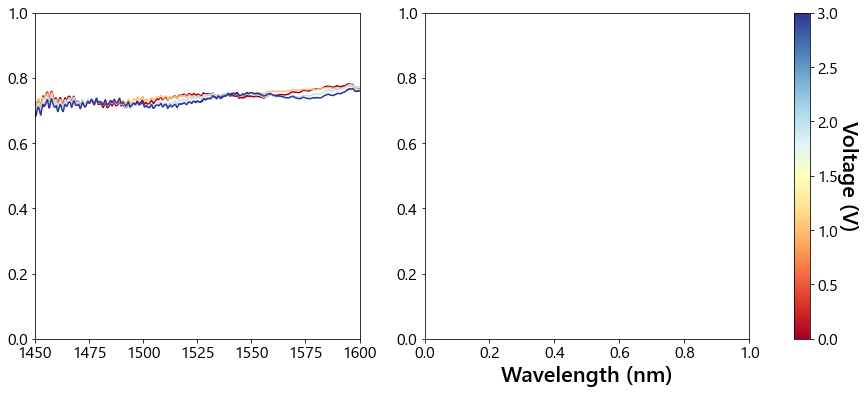

In [93]:
data_dir = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-04-21-Active-Tricouplers\Device-2x3\\1-T1-ON-T2-OFF-Phi-Scan-Photometry\\'
voltages, T1_I1 = read_voltage_scan_spectra(f'{data_dir}I1\\', 'I1', 67, sep=',', delimiter=';')
wav_ref, T1_I1 = np.copy(T1_I1[0][:,0]), np.copy(T1_I1[0][:,1])
_, T1_I2 = read_voltage_scan_spectra(f'{data_dir}I2\\', 'I2', 67, sep=',', delimiter=';')
T1_I2 = np.array([np.interp(wav_ref, T1_I2[i][:,0], T1_I2[i][:,1]) for i in range(len(voltages))])
_, T1_I3 = read_voltage_scan_spectra(f'{data_dir}I3\\', 'I3', 67, sep=',', delimiter=';')
T1_I3 = np.array([np.interp(wav_ref, T1_I3[i][:,0], T1_I3[i][:,1]) for i in range(len(voltages))])

# data_dir = 'C:\\Users\\Pradip\\Desktop\\Sanny-PIC\\2026-04-21-Active-Tricouplers\Device-2x5\\2-T1-OFF-T2-ON-P2-Scan\\'
# _, T2_P2 = read_voltage_scan_spectra(f'{data_dir}5-P2\\', 'P2', 63, sep=',', delimiter=';')
# T2_P2 = np.array([np.interp(wav_ref, T2_P2[i][:,0], T2_P2[i][:,1]) for i in range(len(voltages))])
# _, T2_I1 = read_voltage_scan_spectra(f'{data_dir}2-I1\\', 'I1', 63, sep=',', delimiter=';')
# T2_I1 = np.array([np.interp(wav_ref, T2_I1[i][:,0], T2_I1[i][:,1]) for i in range(len(voltages))])
# _, T2_I2 = read_voltage_scan_spectra(f'{data_dir}3-I2\\', 'I2', 63, sep=',', delimiter=';')
# T2_I2 = np.array([np.interp(wav_ref, T2_I2[i][:,0], T2_I2[i][:,1]) for i in range(len(voltages))])
# _, T2_I3 = read_voltage_scan_spectra(f'{data_dir}4-I3\\', 'I3', 63, sep=',', delimiter=';')
# T2_I3 = np.array([np.interp(wav_ref, T2_I3[i][:,0], T2_I3[i][:,1]) for i in range(len(voltages))])

T1_split = T1_I2/(T1_I1 + T1_I2 + T1_I3)
# T2_split = T2_I2/(T2_I1 + T2_I2 + T2_I3)
wav_ref = 10000000/wav_ref

fig, ax = plt.subplots(1, 2, figsize=(16,6))
vmin, vmax = 0, 3
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
voltages_range = (voltages>=vmin) * (voltages<=vmax)

for i, voltage in enumerate(voltages[voltages_range]):
    color = cmap(norm(voltage))
    ax[0].plot(wav_ref, T1_split[voltages_range][i], color=color)
    # ax[1].plot(wav_ref, T2_split[voltages_range][i], color=color)
ax[0].set_xlim(1450, 1600)
ax[0].set_ylim(0, 1)

# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Voltage (V)", rotation=270, labelpad=20)

plt.show()

matplotlib.colorbar: DEBUG    locator: <matplotlib.colorbar._ColorbarAutoLocator object at 0x0000018FB80F77C0>
matplotlib.colorbar: DEBUG    Using auto colorbar locator <matplotlib.colorbar._ColorbarAutoLocator object at 0x0000018FB80F77C0> on colorbar
matplotlib.colorbar: DEBUG    Setting pcolormesh


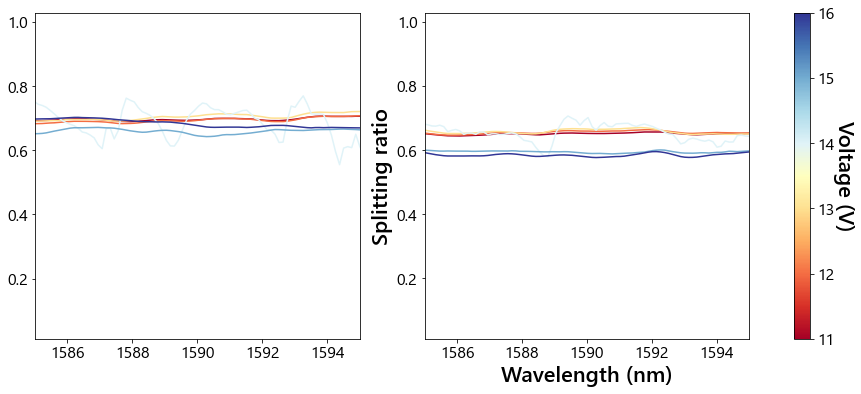

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16,6))
vmin, vmax = 11, 16
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cmap = cm.get_cmap('RdYlBu')  # red → yellow → blue
voltages_range = (voltages>=vmin) * (voltages<=vmax)

for i, voltage in enumerate(voltages[voltages_range]):
    color = cmap(norm(voltage))
    ax[0].plot(wav_ref, T1_split[voltages_range][i], color=color)
    # ax[1].plot(wav_ref, T2_split[voltages_range][i], color=color)
    
for i in range(2):
    ax[i].set_xlim(1585, 1595)
# plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')
plt.ylabel('Splitting ratio')

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Voltage (V)", rotation=270, labelpad=20)

plt.show()

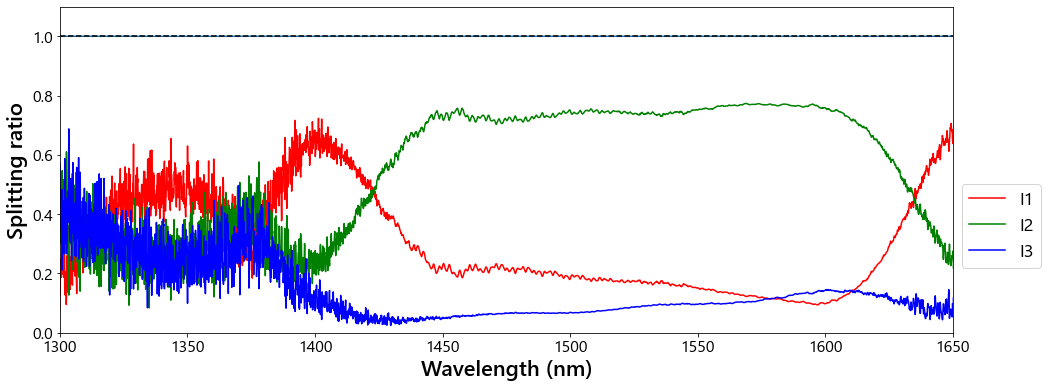

In [91]:
T1_I2_split = T1_I2/(T1_I1 + T1_I2 + T1_I3)
T1_I1_split = T1_I1/(T1_I1 + T1_I2 + T1_I3)
T1_I3_split = T1_I3/(T1_I1 + T1_I2 + T1_I3)
# T2_I2_split = T2_I2/(T2_I1 + T2_I2 + T2_I3)


fig, ax = plt.subplots(1, 1, figsize=(16,6))
i=13
plt.plot(wav_ref, T1_I1_split[i], color='r', label='I1')
plt.plot(wav_ref, T1_I2_split[i], color='g', label='I2')
plt.plot(wav_ref, T1_I3_split[i], color='b', label='I3')
plt.plot(wav_ref, T1_I1_split[i] + T1_I2_split[i]+ T1_I3_split[i])
plt.axhline(1, linestyle='dashed', color='k')

plt.xlim(1300, 1650)
plt.ylim(0, 1.1)
plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')
plt.ylabel('Splitting ratio')


plt.show()

In [61]:
tec.close()
osa.close()
xpow.close()

TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
OSA         : INFO     Disconnected from OSA.
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:1:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {1:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {2:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:3:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {3:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:4:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:4:VOLT:0:OK}
XPOW   

[[ 9.90675054 12.18707743 15.42444615]
 [ 9.98771283 11.59716219 15.78865205]
 [ 9.53627987 10.91719362 14.37533869]
 [ 9.66637896 11.47933008 15.05893896]]
XPOW        : DEBUG    Sent XPOW command: "CH:21:VOLT:9.91" to port "COM6".
XPOW        : DEBUG    COM6answer = {:21:VOLT:9.91:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:21:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {21:9.555:89.3618}
XPOW        : DEBUG    Channel 61 set to 9.906750539581875 V.
XPOW        : DEBUG    Sent XPOW command: "CH:22:VOLT:12.19" to port "COM6".
XPOW        : DEBUG    COM6answer = {:22:VOLT:12.19:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:22:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {22:10.661:100.7572}
XPOW        : DEBUG    Channel 62 set to 12.187077433305358 V.
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:15.42" to port "COM6".
XPOW        : DEBUG    COM6answer = {:1:VOLT:15.42:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:VAL?" to port "COM6".

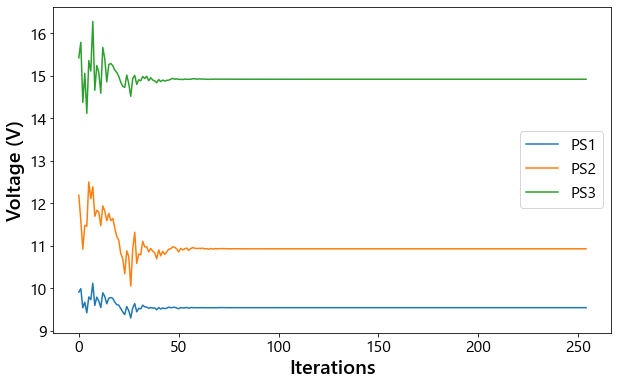

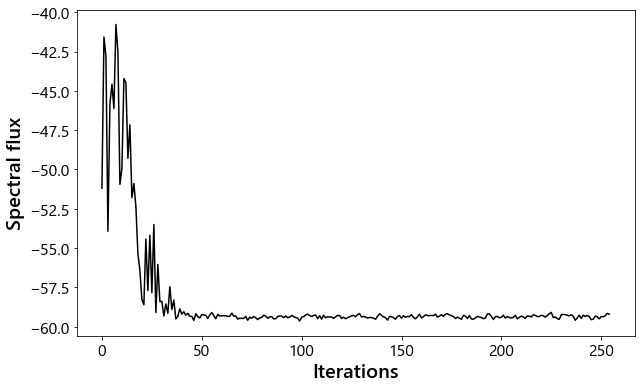

In [47]:
data_dir = "D:\\Active_PIC\\2026-04-16\\"
device_name = "Device6a_1x5Tri"
exp_name = 'amoeba_OSA_TECoff_trial1'
filename_root = data_dir + device_name
initial_voltages = np.array([9.79478587, 11.33916498, 15.0])
channels = [61, 62, 41]
bounds = [(0., 16.), (0., 16.), (0., 16.)]


res, min_metric, all_voltages, min_metrics, temps = PIC.optimize_null_OSA(initial_voltages, channels, osa, xpow, tec, lambda_0=1550, 
                                                                          bandwidth=12, navg=1, plot=False, bounds=bounds, xatol=0.5)

plt.figure(figsize=(10,6))
plt.plot(all_voltages[:,0], label='PS1')
plt.plot(all_voltages[:,1], label='PS2')
plt.plot(all_voltages[:,2], label='PS3')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('Iterations', fontsize=20)
plt.ylabel('Voltage (V)', fontsize=20)
plt.legend(fontsize=16)
plt.show()

plt.figure(figsize=(10,6))
plt.plot(min_metrics, 'k')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('Iterations', fontsize=20)
plt.ylabel('Spectral flux', fontsize=20)
plt.show()

os.makedirs(data_dir, exist_ok=True)
np.save(f"{data_dir}{device_name}_{exp_name}_voltages.npy", all_voltages)
np.save(f"{data_dir}{device_name}_{exp_name}_min.npy", min_metrics)
np.save(f"{data_dir}{device_name}_{exp_name}_temperature.npy", temps)

In [50]:
# osa.close()
tec.off()
tec.close()
osa.close()
xpow.close()

TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
OSA         : INFO     Disconnected from OSA.
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:1:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {1:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {2:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:3:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {3:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:4:VOLT:0" to port "COM4".
XPOW 

# Reduce data

In [2]:
def read_ThorSpectra(path, log=True):
    with open(path) as f:
        text = f.read()

    data = text.split("[Data]\n",1)[1].split("[EndOfFile]",1)[0]

    arr = np.fromstring(data.replace(",", " "), sep=" ")
    arr = arr.reshape(-1,2)
    wav, flux = arr[:,0], arr[:,1]
    if log:
        flux = 10**(flux/10)
    return wav, flux

def crop_spectrum(wav, flux, wav_range):
    ind = np.argwhere((wav>=wav_range[0]) * (wav<=wav_range[1]))
    return wav[ind], flux[ind]

### Passive devices

Straight vs. S-bend

In [3]:
save_dir = f'D:\\Active_PIC\\device_figs\\Passive\\'
wav_range = [1450, 1650]

In [1]:
filepath = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device0_StraightWaveguide_I2_O0_spectrum.csv'
wav_1, flux_1 = read_ThorSpectra(filepath)
wav_1, flux_1 = crop_spectrum(wav_1, flux_1, wav_range)
filepath = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav_2, flux_2 = read_ThorSpectra(filepath)
flux_2 = np.interp(wav_1, wav_2, flux_2)

fig, ax = plt.subplots(2, 1, figsize=(10,6))
ax[0].plot(wav_1, flux_1, label='Straight')
ax[0].plot(wav_1, flux_2, label='S-bend')
ax[1].plot(wav_1, flux_2/flux_1, color='k')
for i in range(2):
    ax[i].xlim(wav_range[0], wav_range[1])
ax[1].xlabel('Wavelength (nm)')
ax[0].ylabel('Power (mW)')
ax[0].ylabel('Ratio')
ax[0].legend()
# plt.savefig(f'{save_dir}Device0_Straight_Sbend_spectra.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

NameError: name 'read_ThorSpectra' is not defined

Parallel waveguides

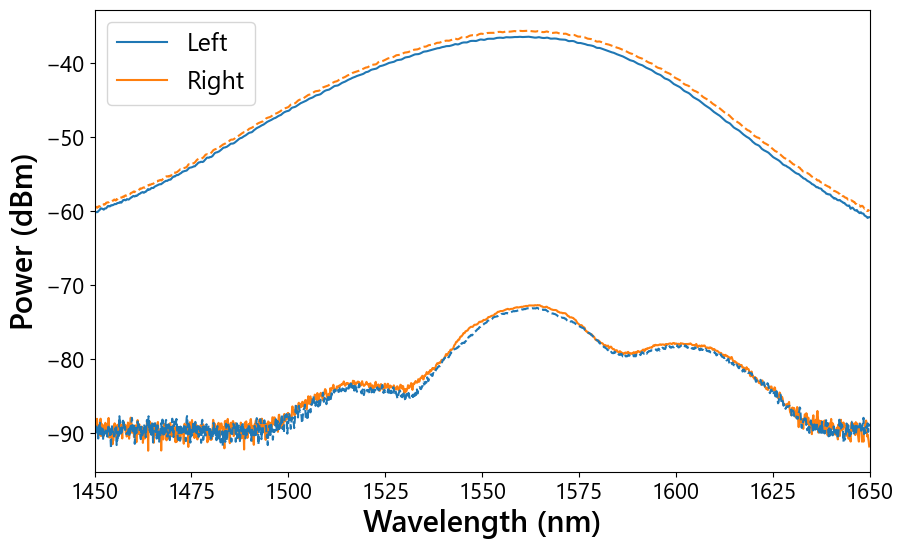

In [164]:
filepath_root = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device1_ParallelWaveguides\\'
filepath_1 = f'{filepath_root}Device1_I4_O2_ParallelWaveguides_spectrum.csv'
filepath_2 = f'{filepath_root}Device1_I4_O3_ParallelWaveguides_spectrum.csv'
filepath_3 = f'{filepath_root}Device1_I5_O2_ParallelWaveguides_spectrum.csv'
filepath_4 = f'{filepath_root}Device1_I5_O3_ParallelWaveguides_spectrum.csv'
wav_1, flux_1 = read_ThorSpectra(filepath_1, log=False)
wav_1, flux_1 = crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = read_ThorSpectra(filepath_2, log=False)
wav_2, flux_2 = crop_spectrum(wav_2, flux_2, wav_range)
wav_3, flux_3 = read_ThorSpectra(filepath_3, log=False)
wav_3, flux_3 = crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = read_ThorSpectra(filepath_4, log=False)
wav_4, flux_4 = crop_spectrum(wav_4, flux_4, wav_range)

plt.figure(figsize=(10,6))
plt.plot(wav_1, flux_1, label='Left', color='C0')
plt.plot(wav_2, flux_2, label='Right', color='C1')
plt.plot(wav_3, flux_3, linestyle='dashed', color='C0')
plt.plot(wav_4, flux_4, linestyle='dashed', color='C1')
plt.xlim(wav_range[0], wav_range[1])
plt.xlabel('Wavelength (nm)')
plt.ylabel('Power (dBm)')
plt.legend()
plt.savefig(f'{save_dir}Device1_ParallelWaveguides_spectra.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

Splitters

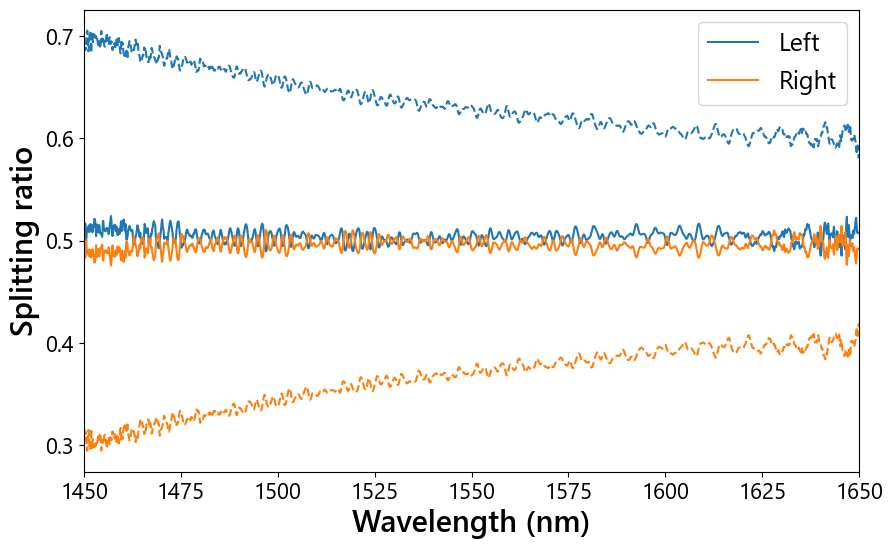

In [165]:
filepath_root = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device2a_Ysplitter\\'
filepath_1 = f'{filepath_root}Device2a_I6_O4_Ysplitter_spectrum.csv'
filepath_2 = f'{filepath_root}Device2a_I6_O5_Ysplitter_spectrum.csv'
filepath_root = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device2b_WINCsplitter\\'
filepath_3 = f'{filepath_root}Device2b_I7_O6_WINCsplitter_spectrum.csv'
filepath_4 = f'{filepath_root}Device2b_I7_O7_WINCsplitter_spectrum.csv'
wav_1, flux_1 = read_ThorSpectra(filepath_1)
wav_1, flux_1 = crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = read_ThorSpectra(filepath_2)

flux_2 = np.interp(wav_1, wav_2, flux_2)
wav_3, flux_3 = read_ThorSpectra(filepath_3)
wav_3, flux_3 = crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = read_ThorSpectra(filepath_4)
flux_4 = np.interp(wav_3, wav_4, flux_4)

plt.figure(figsize=(10,6))
plt.plot(wav_1, flux_1/(flux_1+flux_2), label='Left', color='C0')
plt.plot(wav_1, flux_2/(flux_1+flux_2), label='Right', color='C1')
plt.plot(wav_3, flux_3/(flux_3+flux_4), linestyle='dashed', color='C0')
plt.plot(wav_3, flux_4/(flux_3+flux_4), linestyle='dashed', color='C1')
plt.xlim(wav_range[0], wav_range[1])
plt.xlabel('Wavelength (nm)')
plt.ylabel('Splitting ratio')
plt.legend()
plt.savefig(f'{save_dir}Device2_Splitters_splittingRatio.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

76 deg vs. 53 deg crossing

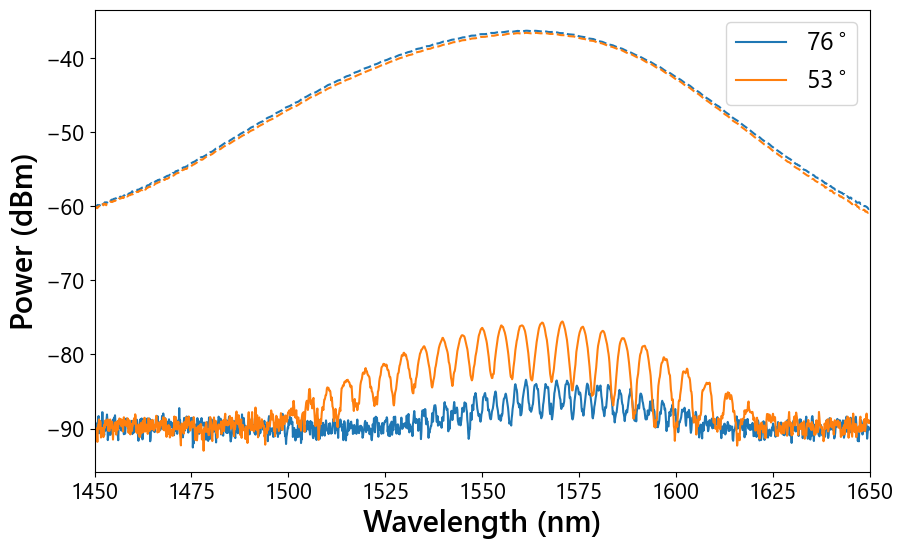

In [166]:
filepath_root = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device3a_76degCrossing\\'
filepath_1 = f'{filepath_root}Device3a_I8_O8_76degCrossing.csv'
filepath_2 = f'{filepath_root}Device3a_I8_O9_76degCrossing.csv'
filepath_root = f'D:\\Active_PIC\\ReverseInjection\\20260304\Device3b_53degCrossing\\'
filepath_3 = f'{filepath_root}Device3a_I9_O10_53degCrossing.csv'
filepath_4 = f'{filepath_root}Device3a_I9_O11_53degCrossing.csv'
wav_1, flux_1 = read_ThorSpectra(filepath_1, log=False)
wav_1, flux_1 = crop_spectrum(wav_1, flux_1, wav_range)
wav_2, flux_2 = read_ThorSpectra(filepath_2, log=False)
wav_2, flux_2 = crop_spectrum(wav_2, flux_2, wav_range)
wav_3, flux_3 = read_ThorSpectra(filepath_3, log=False)
wav_3, flux_3 = crop_spectrum(wav_3, flux_3, wav_range)
wav_4, flux_4 = read_ThorSpectra(filepath_4, log=False)
wav_4, flux_4 = crop_spectrum(wav_4, flux_4, wav_range)

plt.figure(figsize=(10,6))
plt.plot(wav_1, flux_1, label='76$^\circ$', color='C0')
plt.plot(wav_3, flux_3, label='53$^\circ$', color='C1')
plt.plot(wav_2, flux_2, linestyle='dashed', color='C0')
plt.plot(wav_4, flux_4, linestyle='dashed', color='C1')
plt.xlim(wav_range[0], wav_range[1])
plt.xlabel('Wavelength (nm)')
plt.ylabel('Power (dBm)')
plt.legend()
plt.savefig(f'{save_dir}Device3_Crossing_spectra.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

2x3 tricoupler

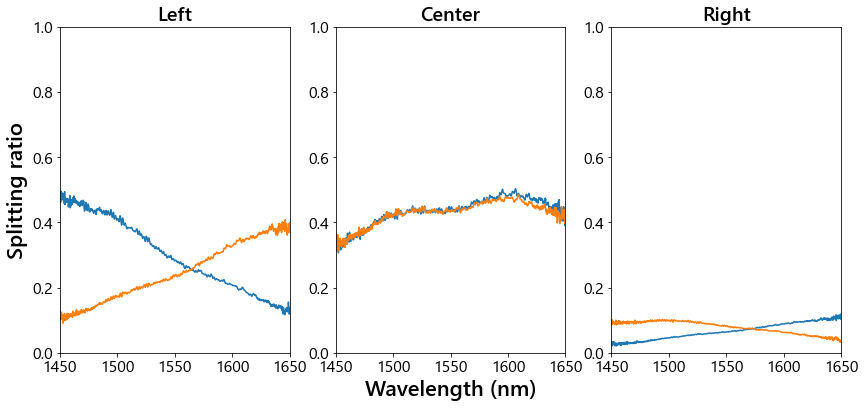

In [11]:
inputs = [16, 17]
outputs = [23, 24, 25]

filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device1_SbendWaveguide_I3_O1_spectrum.csv'
wav, norm = read_ThorSpectra(filepath, log=False)

fig, ax = plt.subplots(1, len(outputs), figsize=(14,6))
output_colors = ['red', 'green', 'purple']
output_names = ['Left', 'Center', 'Right']
for i, output in enumerate(outputs):
    filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device5b_2x3Tri\\Device5b_2x3Tri_I{inputs[0]}_O{output}_spectrum.csv'
    wav_1, flux_1 = read_ThorSpectra(filepath, log=False)

    filepath = f'D:\\Active_PIC\\ReverseInjection\\20260310\\Device5b_2x3Tri\\Device5b_2x3Tri_I{inputs[1]}_O{output}_spectrum.csv'
    wav_2, flux_2 = read_ThorSpectra(filepath, log=False)

    flux_1_interp = np.interp(wav, wav_1, flux_1)
    flux_2_interp = np.interp(wav, wav_2, flux_2)

    ax[i].plot(wav, flux_1_interp/norm, label='Input A', color='C0')
    ax[i].plot(wav, flux_2_interp/norm, label='Input B', color='C1')
    ax[i].set_xlim(1450, 1650)
    ax[i].set_ylim(0, 1)
    # ax[i].set_title(f"Output {chr(ord('A') + i)}")#, color = output_colors[i])
    ax[i].set_title(output_names[i])

ax[1].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('Splitting ratio')
plt.savefig(f'{save_dir}Device5b_2x3Tri_splittingRatio.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()  

Passive chip tricoupler

### Active devices

1x2 MZI: 2x2 MMIs

In [ ]:
data_dir = "D:\\Active_PIC\\ReverseInjection\\"
device_name = "Device4a_1x2MZI_2x2MMI"
input_name = "Device4a_I11_O15_1x2MZI_2x2MMI"
channel = 65
# dataset_name = f"PhaseScan_T2On_I20_O31_Ch{channel}_V0-16"
directory_path = f"{data_dir}{device_name}\\"

os.makedirs(directory_path, exist_ok=True)

voltages = np.arange(0, 16.1, 1)
temps = []
fig, ax = plt.subplots(1, 1, figsize=(10,6))

for voltage in voltages:
    xpow.apply_voltage(channel, voltage)
    time.sleep(2)
    voltage_str = f"{voltage:.3f}".replace('.', 'p')
    spectrum, sigma = osa.read_spectrum(navg=5, plot=False, filename=f"{directory_path}{input_name}_V{voltage_str}")
    temps.append(tec.read_temperature())
    plt.plot(spectrum[0], spectrum[1], label=f"{voltage:0.3f} V")

plt.legend(loc=(1.01, 0.2))
plt.xlabel('Wavelength (nm)')
plt.show()  

np.save(f"{directory_path}{input_name}_voltage.npy", voltages)
np.save(f"{directory_path}{input_name}_temp.npy", temps)